# Used Car Price Predictor
Predicts used car prices in India using Scikit-learn, with a Streamlit app.
## 1. Setup and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

raw_df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
print(raw_df.shape)
raw_df.head()

(4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 2. Data Cleaning

In [2]:
# Remove duplicate listings
df = raw_df.drop_duplicates().reset_index(drop=True)
print("Before:", raw_df.shape, "| After removing duplicates:", df.shape)

# Extract brand and car age
df['brand'] = df['name'].str.split().str[0]
df['car_age'] = 2020 - df['year']          # dataset ends at 2020

# Group rare brands into 'Other'
top_brands = df['brand'].value_counts()
top_brands = top_brands[top_brands >= 30].index
df['brand'] = df['brand'].where(df['brand'].isin(top_brands), 'Other')

df = df.drop(columns=['name', 'year'])
df.head()

Before: (4340, 8) | After removing duplicates: (3577, 8)


,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,13
1,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,13
2,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,8
3,250000,46000,Petrol,Individual,Manual,First Owner,Other,3
4,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,6


## 3. Exploratory Data Analysis

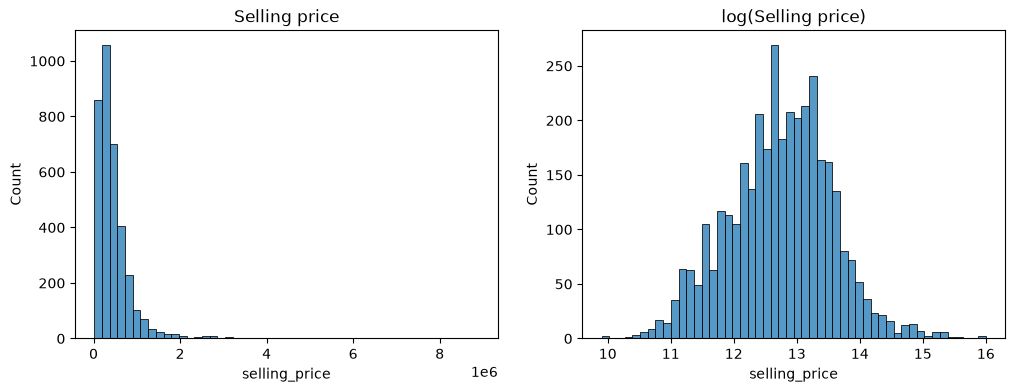

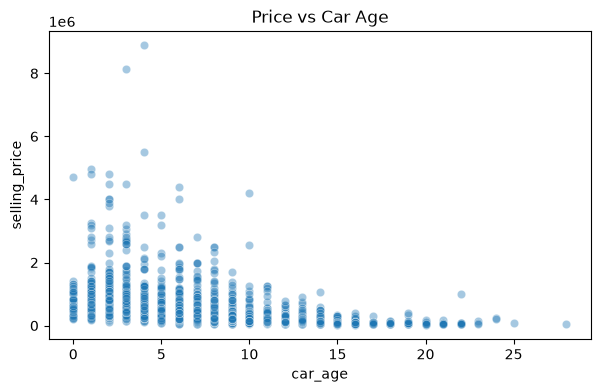

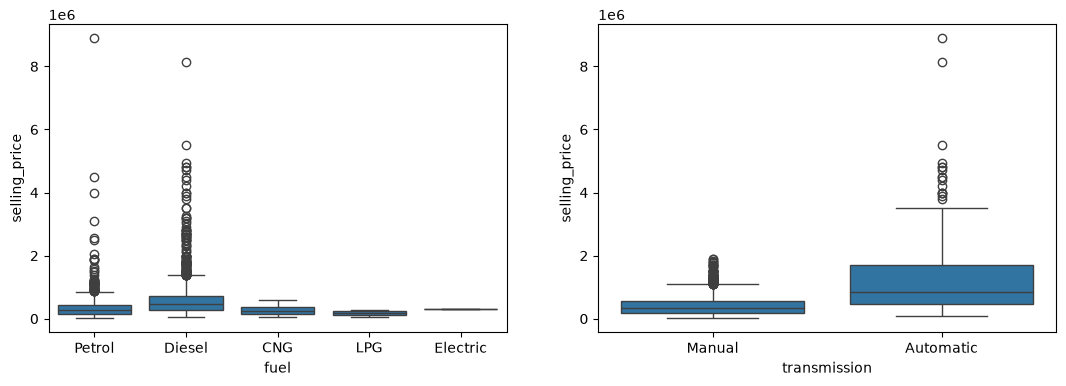

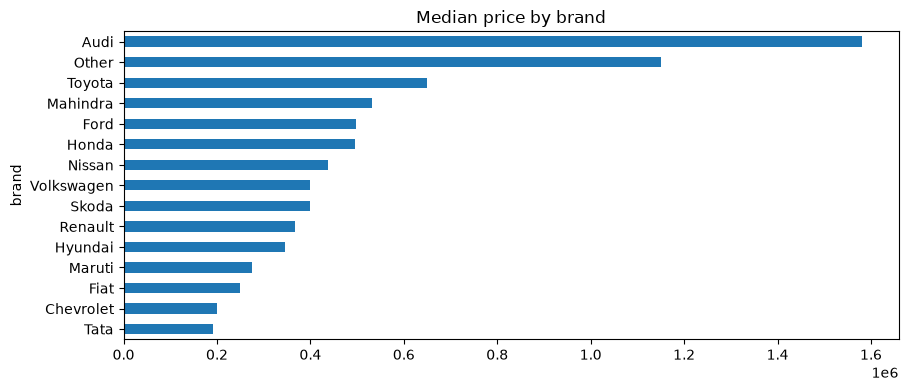

               selling_price  km_driven  car_age
selling_price       1.000000  -0.187359 -0.42426
km_driven          -0.187359   1.000000  0.41749
car_age            -0.424260   0.417490  1.00000


In [3]:
# Plot 1: price distribution, raw vs log
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['selling_price'], bins=50, ax=ax[0])
ax[0].set_title("Selling price")
sns.histplot(np.log1p(df['selling_price']), bins=50, ax=ax[1])
ax[1].set_title("log(Selling price)")
plt.show()

# Plot 2: price vs car age
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='car_age', y='selling_price', alpha=0.4)
plt.title("Price vs Car Age")
plt.show()

# Plot 3: price by fuel type and transmission
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='fuel', y='selling_price', ax=ax[0])
sns.boxplot(data=df, x='transmission', y='selling_price', ax=ax[1])
plt.show()

# Plot 4: median price by brand
plt.figure(figsize=(10, 4))
df.groupby('brand')['selling_price'].median().sort_values().plot(kind='barh')
plt.title("Median price by brand")
plt.show()

print(df[['selling_price', 'km_driven', 'car_age']].corr())

### 3b. Outlier Removal

In [4]:
print(df['km_driven'].describe())
print("km_driven > 300,000:", (df['km_driven'] > 300000).sum())
print("selling_price > 30 lakh:", (df['selling_price'] > 3_000_000).sum())
print("km_driven < 500:", (df['km_driven'] < 500).sum())

# Remove implausible mileage values
df = df[(df['km_driven'] < 300000) & (df['km_driven'] > 500)].reset_index(drop=True)
print("Shape after removing outliers:", df.shape)

count      3577.000000
mean      69250.545709
std       47579.940016
min           1.000000
25%       36000.000000
50%       60000.000000
75%       90000.000000
max      806599.000000
Name: km_driven, dtype: float64
km_driven > 300,000: 7
selling_price > 30 lakh: 25
km_driven < 500: 4
Shape after removing outliers: (3562, 8)


## 4. Baseline Models (brand as a feature)

In [5]:
data = pd.get_dummies(df, columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'], drop_first=True)

X = data.drop('selling_price', axis=1)
y = data['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    for use_log in [False, True]:
        yt = np.log1p(y_train) if use_log else y_train
        model.fit(X_train, yt)
        pred = model.predict(X_test)
        if use_log:
            pred = np.expm1(pred)
        results.append({
            "Model": name,
            "Log target": use_log,
            "R2": round(r2_score(y_test, pred), 3),
            "MAE (Rs)": int(mean_absolute_error(y_test, pred)),
            "RMSE (Rs)": int(np.sqrt(mean_squared_error(y_test, pred))),
        })

pd.DataFrame(results).sort_values("R2", ascending=False)

,Model,Log target,R2,MAE (Rs),RMSE (Rs)
4,Gradient Boosting,False,0.691,147846,291309
5,Gradient Boosting,True,0.671,139910,300711
1,Linear Regression,True,0.649,150502,310606
3,Random Forest,True,0.632,147195,317949
2,Random Forest,False,0.617,158391,324516
0,Linear Regression,False,0.565,191852,345657


In [6]:
rf_base = RandomForestRegressor(n_estimators=200, random_state=42)
scores = cross_val_score(rf_base, X, np.log1p(y), cv=5, scoring='r2')
print("Baseline CV R2 (log price):", scores.round(3), "| mean:", round(scores.mean(), 3))

Baseline CV R2 (log price): [0.752 0.747 0.748 0.712 0.715] | mean: 0.735


## 5. Feature Engineering: Car Model Instead of Brand

In [7]:
exp = raw_df.drop_duplicates().reset_index(drop=True)
exp['model'] = exp['name'].str.split().str[:2].str.join(' ')    # e.g. "Maruti Swift"
exp['car_age'] = 2020 - exp['year']

counts = exp['model'].value_counts()
exp['model'] = exp['model'].where(exp['model'].map(counts) >= 15, 'Other')

exp = exp[(exp['km_driven'] < 300000) & (exp['km_driven'] > 500)]
exp = exp.drop(columns=['name', 'year']).reset_index(drop=True)

exp_data = pd.get_dummies(exp, columns=['fuel', 'seller_type', 'transmission', 'owner', 'model'], drop_first=True)
X_exp = exp_data.drop('selling_price', axis=1)
y_exp = np.log1p(exp_data['selling_price'])

rf_exp = RandomForestRegressor(n_estimators=200, random_state=42)
scores = cross_val_score(rf_exp, X_exp, y_exp, cv=5, scoring='r2')
print("Car-model feature CV R2 (log price):", scores.round(3), "| mean:", round(scores.mean(), 3))

Car-model feature CV R2 (log price): [0.838 0.806 0.8   0.801 0.744] | mean: 0.798


## 6. Final Model and Saving Artifacts

In [8]:
final = raw_df.drop_duplicates().reset_index(drop=True)

final['brand'] = final['name'].str.split().str[0]
final['model'] = final['name'].str.split().str[:2].str.join(' ')
final['car_age'] = 2020 - final['year']

# Common models keep their name; rare models fall back to "<Brand> (other)"
model_cnt = final['model'].map(final['model'].value_counts())
brand_cnt = final['brand'].map(final['brand'].value_counts())
final['model'] = np.where(model_cnt >= 15, final['model'],
                 np.where(brand_cnt >= 15, final['brand'] + " (other)", "Other"))

final = final[(final['km_driven'] < 300000) & (final['km_driven'] > 500)]
df2 = final.drop(columns=['name', 'year', 'brand']).reset_index(drop=True)

data2 = pd.get_dummies(df2, columns=['fuel', 'seller_type', 'transmission', 'owner', 'model'], drop_first=True)
X2 = data2.drop('selling_price', axis=1)
y2 = np.log1p(data2['selling_price'])

rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42)

# 5-fold cross-validation (log price)
scores = cross_val_score(rf, X2, y2, cv=5, scoring='r2')
print("CV R2 (log):", scores.round(3), "| mean:", round(scores.mean(), 3))

# Hold-out test metrics
X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.2, random_state=42)
rf.fit(X_train, y_train)

pred_log = rf.predict(X_test)
actual, pred = np.expm1(y_test), np.expm1(pred_log)

print("Test R2 (rupees):", round(r2_score(actual, pred), 3))
print("Test R2 (log):", round(r2_score(y_test, pred_log), 3))
print("MAE: Rs", int(mean_absolute_error(actual, pred)))
print("Median % error:", round(np.median(np.abs(pred - actual) / actual * 100), 1), "%")

# Save artifacts for the Streamlit app
joblib.dump(rf, "model.pkl", compress=3)
joblib.dump(list(X2.columns), "columns.pkl")
joblib.dump(sorted(df2['model'].unique()), "models_list.pkl")

CV R2 (log): [0.853 0.849 0.815 0.818 0.796] | mean: 0.826
Test R2 (rupees): 0.678
Test R2 (log): 0.812
MAE: Rs 118540
Median % error: 19.2 %


['models_list.pkl']

## 7. Sanity Check on the Saved Model

In [9]:
model = joblib.load("model.pkl")
columns = joblib.load("columns.pkl")

def predict_price(car_model, year, km, fuel, seller, transmission, owner="First Owner"):
    row = pd.DataFrame([{
        "km_driven": km, "car_age": 2020 - year, "fuel": fuel,
        "seller_type": seller, "transmission": transmission,
        "owner": owner, "model": car_model,
    }])
    row = pd.get_dummies(row).reindex(columns=columns, fill_value=0)
    return int(np.expm1(model.predict(row)[0]))

print("Maruti Swift 2015:", predict_price("Maruti Swift", 2015, 50000, "Petrol", "Individual", "Manual"))
print("Toyota Innova 2012:", predict_price("Toyota Innova", 2012, 100000, "Diesel", "Individual", "Manual"))
print("Audi 2016:", predict_price("Audi (other)", 2016, 40000, "Diesel", "Dealer", "Automatic"))

Maruti Swift 2015: 333427
Toyota Innova 2012: 564067
Audi 2016: 2114845
